# Demos for analyzing World Color Survey (WCS)

COG 260: Data, Computation, and The Mind (Yang Xu)

Data source: https://linguistics.berkeley.edu/wcs/data.html

______________________________________________

Import helper function file for WCS data analysis.

In [2]:
from wcs_helper_functions import *

Import relevant Python libraries.

In [32]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy import spatial
from random import random
%matplotlib inline

## Demo 1: Import stimulus (color chip) information in [Munsell space](https://en.wikipedia.org/wiki/Munsell_color_system)

> Stimuli were 330 color chips in Munsell space, each defined along lightness and hue dimensions.

> Each color chip has an index _(from 1 to 330)_ and a coordinate (lightness *(alphabet)*, hue *(integer)*).

In the following section, you will learn how to convert from **(a) index to coordinate** and **(b) coordinate to index**.

______________________________________________

Load chip information in Munsell space. 

`munsellInfo` is a 2-element tuple with dictionary elements.

In [4]:
munsellInfo = readChipData('./WCS_data_core/chip.txt');

### (a) Index &rarr; Coordinate

Access the second dictionary in `munsellInfo`.

In [5]:
indexCoord = munsellInfo[1]

`indexCoord` is a dictionary with **index _(key)_ &rarr; coordinate _(value)_** pairs. For example, to retrieve the Munsell coordinate _(lightness, hue)_ for chip with numerical index 1:

In [6]:
print(indexCoord[1])

('E', '29')


You can also uncomment the following to display full stimulus information (long).

In [7]:
# print(indexCoord)

### (b) Coordinate &rarr; Index

Access the first dictionary in `munsellInfo`.

In [8]:
coordIndex = munsellInfo[0]

`coordIndex` is a dictionary with **coordinate _(key)_ &rarr; index _(value)_** pairs. For example, to access numerical index for the color chip at Munsell coordinate _(D, 11)_:

In [9]:
print(coordIndex['D11'])

258


You can also uncomment the following to display full stimulus information (long).

In [10]:
# print(coordIndex)

## Demo 2: Import stimulus information in [CIELAB space](https://en.wikipedia.org/wiki/Lab_color_space)

> Each of the 330 stimuli can also be mapped to the 3D CIELAB space, where the dimensions are `l` _(lightness)_, `a`, & `b` _(color opponency)_.

> CIELAB Coordinates have a **one-to-one** correspondence with Munsell index, which ranges from 1 to 330.

______________________________________________

Load chip coordinates in CIELAB. 

`cielabCoord` is a dictionary with **index _(key)_ &rarr; CIELAB Coordinate _(value)_** pairs.

In [11]:
cielabCoord = readClabData('./WCS_data_core/cnum-vhcm-lab-new.txt')

For example, to obtain the CIELAB coordinates for chip with numerical index 1:

In [12]:
print(cielabCoord[1])

('61.70', '-4.52', '-39.18')


## Demo 3: Import color naming data
    
> Each of the 330 color chips was named by speakers of 110 different languages.

______________________________________________

Load naming data. 

`namingData` is a hierarchical dictionary organized as follows:

**language _(1 - 110)_ &rarr; speaker _(1 - *range varies per language*)_ &rarr; chip index _(1 - 330)_ &rarr; color term**

In [13]:
namingData = readNamingData('./WCS_data_core/term.txt')

For example, to obtain naming data from language 1 and speaker 1 for all 330 color chips:

In [14]:
namingData[1][1]; # remove semicolon to see data in full

For example, to see how many speakers language 1 has:

In [15]:
len(namingData[1])

25

## Demo 4: Import color foci data
    
> Apart from naming the color chips, each speaker also pointed to foci color chips for each color term they had used.

> **Note**: A single color term may have multiple foci locations.

______________________________________________

Load foci data. 

`fociData` is a hierarchical dictionary organized as follows: 

**language _(1 - 110)_ &rarr; speaker _(1 - *range varies per language*)_ &rarr; color term &rarr; foci coordinates**

In [16]:
fociData = readFociData('./WCS_data_core/foci-exp.txt');

For example, to obtain foci data for language 1 and speaker 1, where each entry shows foci locations for given term: 

In [17]:
fociData[1][1]

{'LF': ['A:0'],
 'WK': ['D:9', 'D:10', 'D:11', 'D:12'],
 'F': ['D:25'],
 'LB': ['J:0'],
 'G': ['F:17'],
 'LE': ['F:1', 'F:2', 'F:3', 'G:1', 'G:2', 'G:3']}

In the above example, foci for term 'LF' is located at coordinate _(A, 0)_ in the Munsell chart.

## Demo 5: Import speaker demographic information

> Most speakers' age _(integer)_ and gender _(M/F)_ information was recorded.

______________________________________________

Load speaker information.

`speakerInfo` is a hierarchical dictionary organized as follows:

**language &rarr; speaker &rarr; (age, gender)**

In [18]:
speakerInfo = readSpeakerData('./WCS_data_core/spkr-lsas.txt')

For example, uncomment the following line to access _(age, gender)_ information for all speakers from language 1:

In [19]:
# speakerInfo[1]

For example, uncomment the following line to access _(age, gender)_ information for speaker 1 from language 1:

In [20]:
# speakerInfo[1][1]

## Demo 6: Visualize color naming from an individual speaker

> Naming patterns from a speaker can be visualized in the stimulus palette _(Munsell space)_.

______________________________________________

Extract an example speaker datum from an example language.

In [21]:
lg61_spk5 = namingData[61][5]

Extract color terms used by that speaker.

In [22]:
terms = lg61_spk5.values()

Encode the color terms into random numbers (for plotting purposes).

In [23]:
encoded_terms = map_array_to(terms, generate_random_values(terms))

Visualize the color naming pattern for that speaker&mdash;each color patch corresponds to extension of a color term. Color scheme is randomized, but the partition of the color space is invariant.

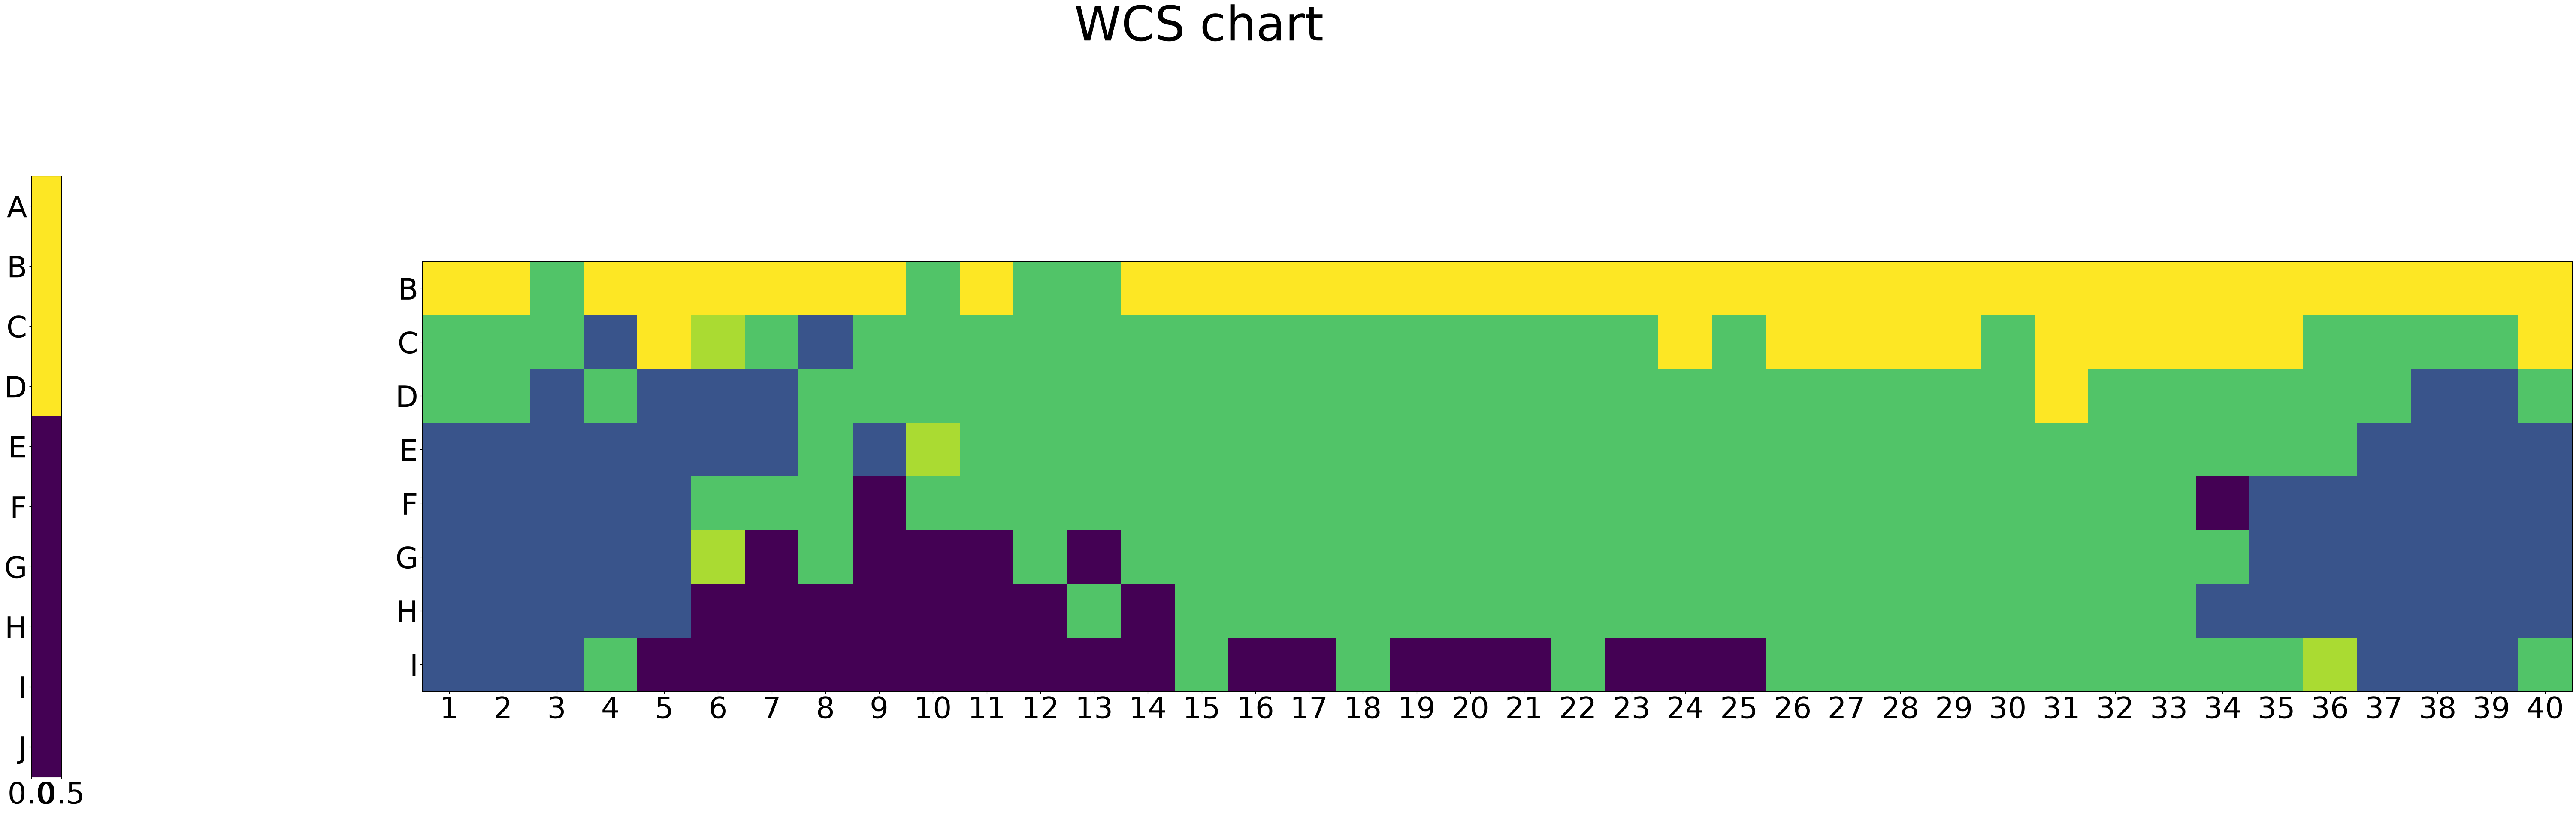

In [24]:
plotValues(encoded_terms)

**Note**: `plotValues()` is a generic function for visualizing various kinds of information on the chart, suited to needs.

Now you are in a position to start exploring this data set - enjoy!

## Experiment 1

In [25]:
# count the number of established color terms of the languages, which we define a language complexity
# for each language, keep record of how many times a term gloss appears as a term used by a speaker to name a Munsell chip
color_words_per_language = dict()
total_languages = len(namingData)
language = 1
while language < total_languages + 1:
    speakers = namingData[language]
    language_color_words = dict()
    # print(len(speakers))
    for speaker in speakers:
        speaker_terms = set(namingData[language][speaker].values())
        for color in speaker_terms:
            if color not in language_color_words:
                language_color_words[color] = 1
            else:
                language_color_words[color] += 1
    # print(language_color_words)
    # number of established terms = the terms that majority of the speakers use
    num_establish_terms = 0
    for color_word in language_color_words.keys():
        if color_word != '*' and language_color_words[color_word] >= 0.5 * len(speakers):
            num_establish_terms += 1
    color_words_per_language['language ' + str(language)] = num_establish_terms
    language += 1
print(color_words_per_language)

{'language 1': 7, 'language 2': 6, 'language 3': 10, 'language 4': 9, 'language 5': 7, 'language 6': 8, 'language 7': 14, 'language 8': 7, 'language 9': 7, 'language 10': 7, 'language 11': 7, 'language 12': 5, 'language 13': 7, 'language 14': 4, 'language 15': 8, 'language 16': 6, 'language 17': 15, 'language 18': 7, 'language 19': 11, 'language 20': 8, 'language 21': 6, 'language 22': 6, 'language 23': 4, 'language 24': 10, 'language 25': 7, 'language 26': 8, 'language 27': 14, 'language 28': 8, 'language 29': 7, 'language 30': 6, 'language 31': 5, 'language 32': 4, 'language 33': 7, 'language 34': 9, 'language 35': 8, 'language 36': 3, 'language 37': 7, 'language 38': 10, 'language 39': 11, 'language 40': 7, 'language 41': 6, 'language 42': 7, 'language 43': 4, 'language 44': 9, 'language 45': 7, 'language 46': 11, 'language 47': 6, 'language 48': 7, 'language 49': 8, 'language 50': 6, 'language 51': 7, 'language 52': 10, 'language 53': 5, 'language 54': 7, 'language 55': 9, 'languag

## Experiment 2

In [26]:
def create_coordinates(s):
    key = str(s).replace(":", "").strip()
    index = coordIndex[key]
    return tuple(float(x) for x in cielabCoord[index])

foci_by_language = {} #chip_foci_identified_per_chip_by_language

for lang_key in fociData:
    foci_by_term = {}
    # term: [list of coords mentioned]
    for speaker in fociData[lang_key]:
        foci = fociData[lang_key][speaker]
        for term in foci:
            if len(foci[term]) > 1:
                c = []
                # convert all of its foci to coordinates
                for chip in foci[term]:
                    c.append(create_coordinates(chip))
                # find the center
                arr = np.array(c)
                f = tuple(arr.mean(axis=0))
            else:
                f = create_coordinates(foci[term][0])
            if term in foci_by_term.keys():
                foci_by_term[term].append(f)
            else:
                foci_by_term[term] = [f]

    foci_by_language[lang_key] = foci_by_term

print(foci_by_language[1])
#foci_by_language is a dictionary of [language] --> [colour terms] --> [chip coordinates]

{'LF': [(96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (96.0, -0.06, 0.06), (np.float64(93.53999999999999), np.float64(-0.055), np.float64(0.06)), (96.0, -0.06, 0.06)], 'WK': [(np.float64(71.6), np.float64(-5.3925), np.float64(85.5875)), (61.7, 49.42, 18.23), (61.7, 46.38, 35.47), (61.7, 44.69, 79.79), (81.35, -3.69, 100.18), (np.float64(71.6), np.float64(33.8875), np.float64(32.1375)), (91.08, -12.17, 45.9), (61.7, 48.53, 25.92), (81.35, -10.94, 87.9), (71.6, 40.04, -2.7), (np.float64(81.35), np.float64(21.82), np.float64(17.836000000000002)), (np.float64(71.6), np.float64(28.505000000000003), np.f

In [30]:
df = pd.DataFrame(
    [
        {
            "language": language,
            "term": term,
            "chip": chip,

        }
        for language, terms in foci_by_language.items()
        for term, chips in terms.items()
        for chip in chips

    ],
    columns=["language", "term", "chip"],
)

print(df)

       language term                                  chip
0             1   LF                   (96.0, -0.06, 0.06)
1             1   LF                   (96.0, -0.06, 0.06)
2             1   LF                   (96.0, -0.06, 0.06)
3             1   LF                   (96.0, -0.06, 0.06)
4             1   LF                   (96.0, -0.06, 0.06)
...         ...  ...                                   ...
17887       110   CH                 (20.54, 10.16, 21.44)
17888       110   CH               (30.77, 16.035, 32.035)
17889       110    M  (51.57, 24.725, -35.370000000000005)
17890       110   RI                 (20.54, 13.28, 18.21)
17891       110    S    (46.394999999999996, -0.03, 0.035)

[17892 rows x 3 columns]


In [39]:
# For each lang
# for each term
# filter out terms with  less than 2 (?) foci identified
    # find center /column mean
    # take euclidean distance from each foci to mean, square and sum, divide by length of foci list
lang_agreement = {}
for lang in foci_by_language:
    term_agreement = []
    for term in foci_by_language[lang]:
        arr = np.array(foci_by_language[lang][term])
        center = arr.mean(axis=0)
        distance = []
        for coord in foci_by_language[lang][term]:
            distance.append(spatial.distance.euclidean(center, coord))
        distance = np.array(distance)
        term_agreement.append(distance.mean())
    lang_agreement[lang] = np.array(term_agreement).mean()

print(lang_agreement)









{1: np.float64(19.20849729927269), 2: np.float64(16.196523568227335), 3: np.float64(19.792220623705134), 4: np.float64(11.835628621603318), 5: np.float64(12.947677134102994), 6: np.float64(13.684288410461663), 7: np.float64(11.536313112749792), 8: np.float64(16.705274982701997), 9: np.float64(19.489265779865114), 10: np.float64(19.748823980640683), 11: np.float64(19.9486602678277), 12: np.float64(12.961352907332875), 13: np.float64(14.307832207847557), 14: np.float64(5.956964235244948), 15: np.float64(16.566838640586873), 16: np.float64(11.761477821643604), 17: np.float64(11.77460117921928), 18: np.float64(24.37215430958378), 19: np.float64(13.725083987163744), 20: np.float64(11.305324521354239), 21: np.float64(11.45953349282016), 22: np.float64(16.73381889480814), 23: np.float64(12.25130237803439), 24: np.float64(13.5371564577623), 25: np.float64(11.69275917220567), 26: np.float64(14.497767307212237), 27: np.float64(10.745582408120155), 28: np.float64(8.408386491921407), 29: np.float6